# Ποιο LLM αναγνωρίζει σαρκασμό; Αξιολόγηση στο `sarcasm_dataset.csv`


**Τι μετράμε.** Για κάθε πρόταση δίνουμε στο μοντέλο την ερώτηση της στήλης `prompt` και κοιτάμε στο τελευταίο token
$d = \text{logit(Yes)} - \text{logit(No)}$  ( $d>0$: «σαρκαστικό» ).

| μετρική | ορισμός (ανά τριάδα P/S/N) | τύχη |
|---|---|---|
| **Triple accuracy** (κύρια) | $d(S) > d(P)$ **και** $d(S) > d(N)$ | 33% |
| S > P | η **κατάσταση** αλλάζει την απάντηση | 50% |
| S > N | η **φράση** αλλάζει την απάντηση | 50% |
| Balanced accuracy | $d>0$ ⇒ «Yes»· μέσος όρος σωστών σε S και σε P/N | 50% |

Διαστήματα εμπιστοσύνης 95% με bootstrap πάνω στις τριάδες. Καλύτερο μοντέλο = υψηλότερη triple accuracy στο `discovery`.

In [ ]:
%pip install -q -U accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.5 MB/s eta 0:00:00


## 1. Ρυθμίσεις και δεδομένα

In [ ]:
import gc, os, shutil, time, html, zipfile
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ΚΑΜΙΑ - άλλαξε runtime σε T4 GPU!")

MODELS = [
    ("Qwen/Qwen2.5-3B-Instruct", False),
    ("Qwen/Qwen3-4B", False),
    ("Qwen/Qwen2.5-7B-Instruct", True),
    ("Qwen/Qwen3-8B", True),
]
BATCH_SIZE = 16
N_BOOT = 2000
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

CSV_PATH = "sarcasm_dataset.csv"
if not os.path.exists(CSV_PATH):
    from google.colab import files
    print("Ανέβασε το sarcasm_dataset.csv:")
    CSV_PATH = list(files.upload())[0]

df = pd.read_csv(CSV_PATH)
need = {"id", "triple_id", "condition", "prompt", "sarcastic", "positive_frame", "split"}
assert need <= set(df.columns), f"Λείπουν στήλες: {need - set(df.columns)}"
assert (df.groupby("triple_id").condition.apply(lambda c: sorted(c) == ["N", "P", "S"])).all(), "Κάθε τριάδα πρέπει να έχει P, S, N"
print(f"{len(df)} προτάσεις, {df.triple_id.nunique()} τριάδες  |  "
      + ", ".join(f"{k}: {v}" for k, v in df.drop_duplicates('triple_id').split.value_counts().items()) + " τριάδες")

GPU: Tesla T4
Ανέβασε το sarcasm_dataset.csv:


Saving sarcasm_dataset.csv to sarcasm_dataset.csv
690 προτάσεις, 230 τριάδες  |  discovery: 184, heldout: 46 τριάδες


## 2. Συναρτήσεις

In [ ]:
def yn_ids(tok):
    pick = lambda ws: [t[0] for t in (tok.encode(w, add_special_tokens=False) for w in ws) if len(t) == 1]
    return pick(["Yes", "yes"]), pick(["No", "no"])


def chat_text(tok, prompt):
    return tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=False)


@torch.no_grad()
def score(model, tok, prompts):
    """d = logsumexp(Yes, yes) - logsumexp(No, no) στο τελευταίο token, για κάθε prompt."""
    Y, N = yn_ids(tok)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    texts = [chat_text(tok, p) for p in prompts]
    order = np.argsort([len(t) for t in texts])
    d = np.zeros(len(texts))
    for i in range(0, len(texts), BATCH_SIZE):
        idx = order[i:i + BATCH_SIZE]
        enc = tok([texts[j] for j in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        pos = (enc.attention_mask.cumsum(-1) - 1).clamp(min=0)
        try:
            out = model(**enc, position_ids=pos, logits_to_keep=1)
        except TypeError:
            out = model(**enc, position_ids=pos)
        lg = out.logits[:, -1, :].float()
        d[idx] = (torch.logsumexp(lg[:, Y], -1) - torch.logsumexp(lg[:, N], -1)).cpu().numpy()
    return d


def triple_table(sub):
    """Μία γραμμή ανά τριάδα: d(P), d(S), d(N)."""
    return sub.pivot(index="triple_id", columns="condition", values="d")[["P", "S", "N"]].to_numpy()


def metrics(T):
    """T: [τριάδες, 3] με στήλες P, S, N. Επιστρέφει dict με τις 4 μετρικές (σε %)."""
    P, S, N = T[..., 0], T[..., 1], T[..., 2]
    tpr = (S > 0).mean(-1)
    tnr = ((P <= 0).mean(-1) + (N <= 0).mean(-1)) / 2
    return {"triple_acc": 100 * ((S > P) & (S > N)).mean(-1), "S>P": 100 * (S > P).mean(-1),
            "S>N": 100 * (S > N).mean(-1), "balanced_acc": 100 * (tpr + tnr) / 2}


def with_ci(T, seed=0):
    """Μετρικές + 95% διάστημα (bootstrap πάνω στις τριάδες)."""
    point = metrics(T)
    idx = np.random.default_rng(seed).integers(0, len(T), (N_BOOT, len(T)))
    boot = metrics(T[idx])
    return {k: (float(point[k]), *np.percentile(boot[k], [2.5, 97.5])) for k in point}


def delete_from_cache(name):
    path = os.path.expanduser("~/.cache/huggingface/hub/models--" + name.replace("/", "--"))
    shutil.rmtree(path, ignore_errors=True)


def load(name, four_bit):
    tok = AutoTokenizer.from_pretrained(name)
    kw = dict(device_map="cuda", low_cpu_mem_usage=True)
    if four_bit:
        kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    else:
        kw["torch_dtype"] = torch.float16
    return tok, AutoModelForCausalLM.from_pretrained(name, **kw).eval()

## 3. Τρέξιμο όλων των μοντέλων (αποθηκεύει μετά από κάθε μοντέλο)

In [ ]:
preds, timing = [], []
for name, four_bit in MODELS:
    short = name.split("/")[-1]
    print(f"\n===== {short} {'(4-bit)' if four_bit else ''} =====")
    model = tok = None
    try:
        t0 = time.time()
        tok, model = load(name, four_bit)
        t1 = time.time()
        d = score(model, tok, df.prompt.tolist())
        t2 = time.time()
    except Exception as e:
        print(f"  !! Απέτυχε: {type(e).__name__}: {str(e)[:300]}")
        continue
    finally:
        del model, tok
        gc.collect(); torch.cuda.empty_cache(); delete_from_cache(name)
    p = df[["id", "triple_id", "condition", "sarcastic", "positive_frame", "split", "text"]].copy()
    p["model"], p["d"] = short, d
    p["prediction"] = np.where(d > 0, "Yes", "No")
    preds.append(p)
    pd.concat(preds).to_csv(f"{OUT_DIR}/predictions.csv", index=False)
    timing.append((short, (t1 - t0) / 60, (t2 - t1) / 60))
    m = metrics(triple_table(p[p.split == "discovery"]))
    print(f"  φόρτωση {(t1 - t0) / 60:.1f} λ., μετρήσεις {(t2 - t1) / 60:.1f} λ.  |  "
          f"triple acc (discovery) {m['triple_acc']:.0f}%")

pred = pd.concat(preds, ignore_index=True)
MODEL_ORDER = [m for m in dict.fromkeys(pred.model)]


===== Qwen2.5-3B-Instruct  =====


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (36 outputs left out)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

  φόρτωση 5.0 λ., μετρήσεις 0.7 λ.  |  triple acc (discovery) 83%


## 4. Συνολικός πίνακας

In [ ]:
rows = []
for m in MODEL_ORDER:
    for split in ["discovery", "heldout", "all"]:
        sub = pred[pred.model == m] if split == "all" else pred[(pred.model == m) & (pred.split == split)]
        T = triple_table(sub)
        r = {"model": m, "split": split, "triples": len(T)}
        for k, (v, lo, hi) in with_ci(T).items():
            r[k], r[k + "_lo"], r[k + "_hi"] = round(v, 1), round(lo, 1), round(hi, 1)
        r.update({f"mean_d_{c}": round(sub[sub.condition == c].d.mean(), 2) for c in "PSN"})
        rows.append(r)
summary = pd.DataFrame(rows)
summary.to_csv(f"{OUT_DIR}/summary.csv", index=False)

def fmt(r, k):
    return f"{r[k]:.0f}% [{r[k + '_lo']:.0f}-{r[k + '_hi']:.0f}]"

show = summary[summary.split != "all"].copy()
nice = pd.DataFrame({"model": show.model, "split": show.split, "τριάδες": show.triples,
                     **{lab: show.apply(lambda r: fmt(r, k), axis=1) for k, lab in
                        [("triple_acc", "Triple acc (τύχη 33%)"), ("S>P", "S>P (50%)"),
                         ("S>N", "S>N (50%)"), ("balanced_acc", "Balanced acc (50%)")]},
                     "μέσο d: P / S / N": show.apply(lambda r: f"{r.mean_d_P:+.1f} / {r.mean_d_S:+.1f} / {r.mean_d_N:+.1f}", axis=1)})
display(nice.reset_index(drop=True))

disc = summary[summary.split == "discovery"].set_index("model")
BEST = disc.triple_acc.idxmax()
held = summary[(summary.split == "heldout")].set_index("model")
print(f"\n>>> Καλύτερο μοντέλο (triple accuracy στο discovery): {BEST}  "
      f"({disc.loc[BEST, 'triple_acc']:.0f}%, heldout {held.loc[BEST, 'triple_acc']:.0f}%)")
print(">>> Ίδιο και στο heldout;", "ΝΑΙ" if held.triple_acc.idxmax() == BEST else f"ΟΧΙ (εκεί: {held.triple_acc.idxmax()})")

,model,split,τριάδες,Triple acc (τύχη 33%),S>P (50%),S>N (50%),Balanced acc (50%),μέσο d: P / S / N
0,Qwen2.5-3B-Instruct,discovery,184,67% [61-74],98% [95-100],67% [61-74],52% [51-54],-19.0 / -11.2 / -14.2
1,Qwen2.5-3B-Instruct,heldout,46,72% [59-85],98% [94-100],72% [59-85],58% [53-64],-17.4 / -5.5 / -10.4
2,Qwen3-4B,discovery,184,82% [76-87],94% [90-97],85% [80-90],60% [58-62],+5.3 / +22.1 / +14.0
3,Qwen3-4B,heldout,46,91% [83-98],96% [89-100],94% [85-100],51% [50-53],+28.1 / +30.4 / +20.8
4,Qwen2.5-7B-Instruct,discovery,184,83% [77-89],100% [98-100],84% [78-89],80% [76-83],-7.3 / +4.4 / -4.1
5,Qwen2.5-7B-Instruct,heldout,46,98% [94-100],98% [94-100],100% [100-100],70% [65-75],+3.2 / +13.9 / -0.1
6,Qwen3-8B,discovery,184,83% [78-89],95% [92-98],84% [79-89],63% [61-65],+0.4 / +11.0 / +5.1
7,Qwen3-8B,heldout,46,87% [76-96],100% [100-100],87% [76-96],53% [51-56],+8.5 / +18.0 / +11.3



>>> Καλύτερο μοντέλο (triple accuracy στο discovery): Qwen2.5-7B-Instruct  (83%, heldout 98%)
>>> Ίδιο και στο heldout; ΝΑΙ


## 5. Διαγράμματα (σώζονται και ως PNG στον φάκελο `results`)

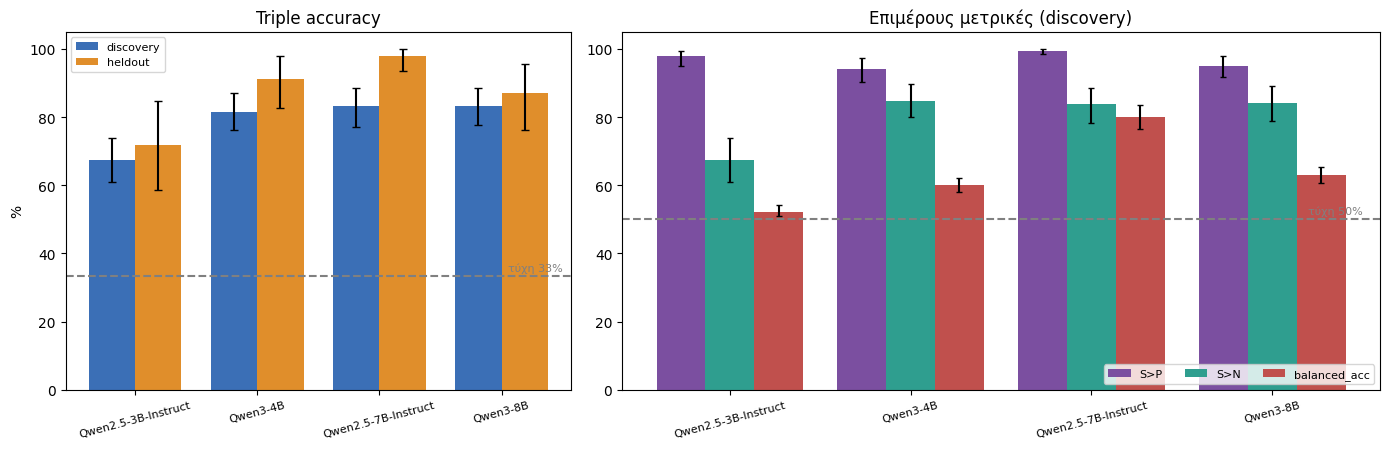

/tmp/ipykernel_616/3979268768.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hm = pred.groupby(["model", "positive_frame"]).apply(lambda g: metrics(triple_table(g))["triple_acc"]).unstack()


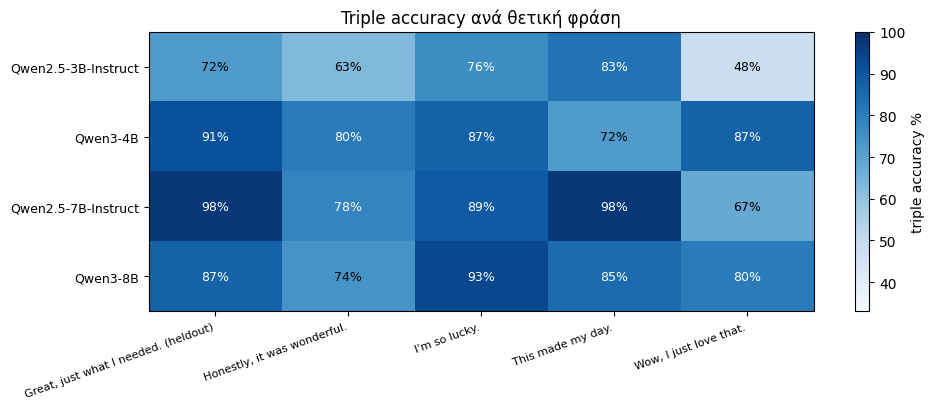

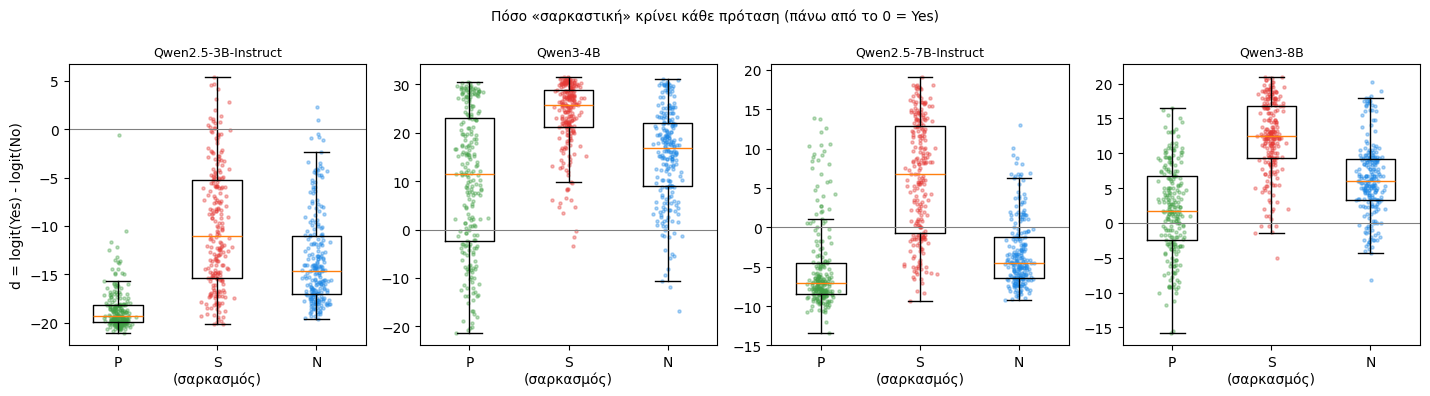

In [ ]:
COLORS = {"discovery": "#3b6fb6", "heldout": "#e08e2b"}
x = np.arange(len(MODEL_ORDER))

# --- (α) triple accuracy ανά μοντέλο ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
for i, split in enumerate(["discovery", "heldout"]):
    s = summary[summary.split == split].set_index("model").loc[MODEL_ORDER]
    ax.bar(x + (i - 0.5) * 0.38, s.triple_acc, 0.38, label=split, color=COLORS[split],
           yerr=[s.triple_acc - s.triple_acc_lo, s.triple_acc_hi - s.triple_acc], capsize=3)
ax.axhline(100 / 3, ls="--", c="gray"); ax.text(len(x) - 0.5, 100 / 3 + 1.5, "τύχη 33%", ha="right", color="gray", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(MODEL_ORDER, rotation=15, fontsize=8); ax.set_ylim(0, 105)
ax.set_ylabel("%"); ax.set_title("Triple accuracy"); ax.legend(fontsize=8)

# --- (β) οι μετρικές με τύχη 50% (discovery) ---
ax = axes[1]
s = summary[summary.split == "discovery"].set_index("model").loc[MODEL_ORDER]
for i, (k, col) in enumerate([("S>P", "#7b4fa0"), ("S>N", "#2f9e8f"), ("balanced_acc", "#c0504d")]):
    ax.bar(x + (i - 1) * 0.27, s[k], 0.27, label=k, color=col, yerr=[s[k] - s[k + "_lo"], s[k + "_hi"] - s[k]], capsize=2)
ax.axhline(50, ls="--", c="gray"); ax.text(len(x) - 0.5, 51.5, "τύχη 50%", ha="right", color="gray", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(MODEL_ORDER, rotation=15, fontsize=8); ax.set_ylim(0, 105)
ax.set_title("Επιμέρους μετρικές (discovery)"); ax.legend(fontsize=8, ncol=3, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_accuracy.png", dpi=150); plt.show()

# --- (γ) heatmap μοντέλο x φράση ---
hm = pred.groupby(["model", "positive_frame"]).apply(lambda g: metrics(triple_table(g))["triple_acc"]).unstack()
hm = hm.loc[MODEL_ORDER]
fig, ax = plt.subplots(figsize=(10, 0.6 * len(hm) + 1.8))
im = ax.imshow(hm.values.astype(float), cmap="Blues", vmin=33, vmax=100, aspect="auto")
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 75 else "black", fontsize=9)
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels([c + (" (heldout)" if c in set(df[df.split == "heldout"].positive_frame) else "") for c in hm.columns], rotation=20, fontsize=8, ha="right")
ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index, fontsize=9)
plt.colorbar(im, ax=ax, label="triple accuracy %"); ax.set_title("Triple accuracy ανά θετική φράση")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_per_frame.png", dpi=150); plt.show()

# --- (δ) κατανομή του d ανά condition ---
fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(3.6 * len(MODEL_ORDER), 4), sharey=False)
axes = np.atleast_1d(axes)
for ax, m in zip(axes, MODEL_ORDER):
    sub = pred[pred.model == m]
    data = [sub[sub.condition == c].d for c in "PSN"]
    ax.boxplot(data, widths=0.5, showfliers=False)
    for i, (dd, col) in enumerate(zip(data, ["#43a047", "#e53935", "#1e88e5"])):
        ax.scatter(np.random.default_rng(i).normal(i + 1, 0.06, len(dd)), dd, s=5, alpha=0.35, color=col)
    ax.axhline(0, c="gray", lw=0.8)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["P", "S\n(σαρκασμός)", "N"]); ax.set_title(m, fontsize=9)
axes[0].set_ylabel("d = logit(Yes) - logit(No)")
plt.suptitle("Πόσο «σαρκαστική» κρίνει κάθε πρόταση (πάνω από το 0 = Yes)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_d_distribution.png", dpi=150); plt.show()

## 6. Παραδείγματα: input → output του καλύτερου μοντέλου

In [ ]:
def show_examples(model_name, n=6, seed=1):
    sub = pred[pred.model == model_name]
    ids = sub.drop_duplicates("triple_id").sample(n, random_state=seed).triple_id
    bg = {"P": "#e8f5e9", "S": "#fff3e0", "N": "#e3f2fd"}
    out = [f"<h4>{model_name}</h4><table style='border-collapse:collapse;font-size:13px;color:#111;background:#fff'>"
           "<tr><th>τριάδα</th><th>cond</th><th style='text-align:left'>πρόταση</th><th>σωστό</th>"
           "<th>d</th><th>απάντηση</th><th>τριάδα σωστή;</th></tr>"]
    for tid in ids:
        g = sub[sub.triple_id == tid].set_index("condition")
        ok = g.loc["S", "d"] > g.loc["P", "d"] and g.loc["S", "d"] > g.loc["N", "d"]
        for c in "PSN":
            r = g.loc[c]
            right = (r.prediction == "Yes") == bool(r.sarcastic)
            out.append(f"<tr style='background:{bg[c]};color:#111'><td>{tid}</td><td><b>{c}</b></td>"
                       f"<td style='text-align:left'>{html.escape(r.text)}</td><td>{'Yes' if r.sarcastic else 'No'}</td>"
                       f"<td>{r.d:+.2f}</td><td style='color:{'green' if right else 'red'}'><b>{r.prediction}</b></td>"
                       f"<td>{('✔' if ok else '✘') if c == 'S' else ''}</td></tr>")
    out.append("</table>")
    display(HTML("".join(out)))

show_examples(BEST)

τριάδα,cond,πρόταση,σωστό,d,απάντηση,τριάδα σωστή;
78,P,"Today was all about friendly neighbors. Honestly, it was wonderful.",No,-9.12,No,
78,S,"Today was all about noisy neighbors. Honestly, it was wonderful.",Yes,+0.25,Yes,✔
78,N,"Today was all about noisy neighbors. Honestly, it was awful.",No,-3.87,No,
150,P,"Today was all about a clean car. Wow, I just love that.",No,-8.62,No,
150,S,"Today was all about a flat tire. Wow, I just love that.",Yes,+8.12,Yes,✔
150,N,"Today was all about a flat tire. Wow, I just hate that.",No,+1.00,Yes,
171,P,"Today was all about my package arriving early. Great, just what I needed.",No,+6.75,Yes,
171,S,"Today was all about my package getting lost. Great, just what I needed.",Yes,+17.50,Yes,✔
171,N,"Today was all about my package getting lost. Great, that ruined everything.",No,+6.75,Yes,
227,P,Today was all about a clean desk. This made my day.,No,-6.50,No,


## 7. Χρόνοι και κατέβασμα όλων των αρχείων

In [ ]:
print("Χρόνοι (λεπτά):")
for m, tl, tr in timing:
    print(f"  {m:24s} φόρτωση {tl:5.1f}   μετρήσεις {tr:5.1f}")

zip_path = "sarcasm_eval_results.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    for f in os.listdir(OUT_DIR):
        z.write(os.path.join(OUT_DIR, f), f)
print("\nΑρχεία:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Εκτός Colab: τα αρχεία είναι στο", zip_path)

Χρόνοι (λεπτά):
  Qwen2.5-3B-Instruct      φόρτωση   1.4   μετρήσεις   0.2
  Qwen3-4B                 φόρτωση   2.2   μετρήσεις   0.3
  Qwen2.5-7B-Instruct      φόρτωση   3.9   μετρήσεις   0.7
  Qwen3-8B                 φόρτωση   5.0   μετρήσεις   0.7

Αρχεία: ['fig_accuracy.png', 'fig_d_distribution.png', 'fig_per_frame.png', 'predictions.csv', 'summary.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>